# 01 - Data understanding (EDA)
CRISP-DM phase 2. Every figure ends with a takeaway that feeds a modelling decision. Data: 12,000 sessions, 17 inputs + `Converted`.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
sys.path.insert(0, str(Path.cwd()))
from src.config import load_settings
from src.data.loader import load_sessions, stratified_split
from src.features.engineering import add_engineered_features
from src.utils import metrics as M
S = load_settings()
df = load_sessions(S)

In [2]:
print(df.shape, 'duplicates:', int(df.duplicated().sum()), 'missing cells:', int(df.isna().sum().sum()))
rate = df.Converted.mean()
print(f'conversion rate {rate:.3%} ({int(df.Converted.sum())} purchases)  -> majority-class accuracy {1-rate:.3%}')
df.describe().T.round(3)

(12000, 18) duplicates: 0 missing cells: 0
conversion rate 15.717% (1886 purchases)  -> majority-class accuracy 84.283%


,count,mean,std,min,25%,50%,75%,max
Administrative,12000.0,1.889,1.465,0.0,1.000,2.000,3.000,11.000
Administrative_Duration,12000.0,42.312,49.032,0.0,11.769,28.511,56.384,659.468
Informational,12000.0,0.546,0.755,0.0,0.000,0.000,1.000,6.000
Informational_Duration,12000.0,13.548,25.074,0.0,0.000,0.000,19.934,397.166
ProductRelated,12000.0,19.832,13.171,0.0,11.000,17.000,25.000,156.000
ProductRelated_Duration,12000.0,723.097,763.562,0.0,268.159,499.426,902.039,10154.159
BounceRates,12000.0,0.021,0.016,0.0,0.008,0.020,0.032,0.089
ExitRates,12000.0,0.054,0.026,0.0,0.036,0.054,0.072,0.158
PageValues,12000.0,12.229,25.859,0.0,0.000,0.000,12.913,418.114
SpecialDay,12000.0,0.061,0.205,0.0,0.000,0.000,0.000,1.000


**Takeaway:** clean file (no duplicates / missing values). Only ~1 in 6.4 sessions buys, so a model that always says "no purchase" is 84.3% accurate and captures nobody. Accuracy is the wrong headline metric; PR-AUC and recall on buyers are used instead.

           ProductRelated  ProductRelated_Duration  ...  BounceRates  Administrative
Converted                                           ...                             
0                    15.0                  447.737  ...        0.022             2.0
1                    32.0                  933.782  ...        0.007             2.0

[2 rows x 5 columns]


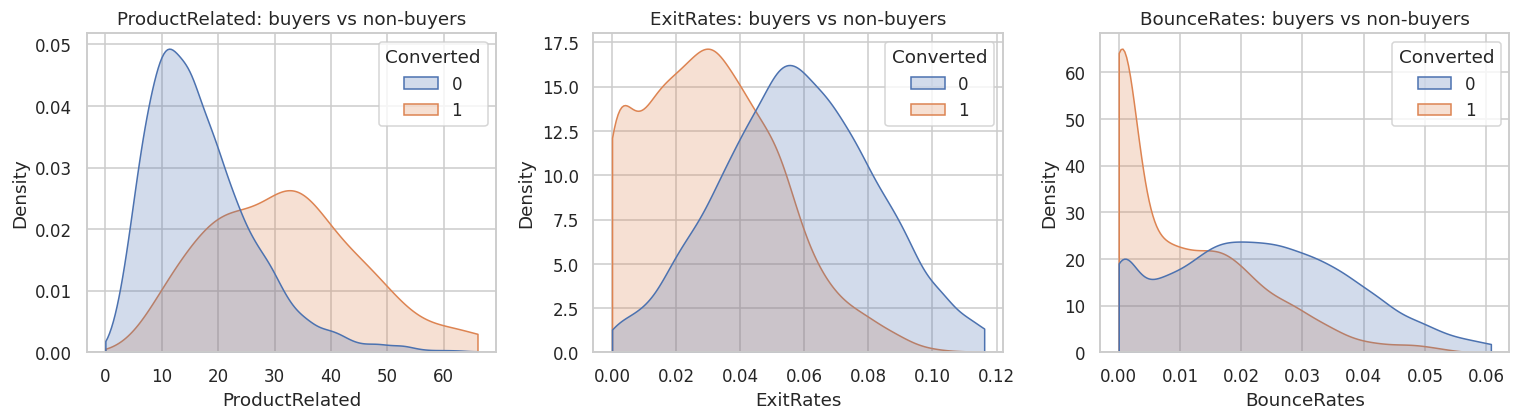

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['ProductRelated', 'ExitRates', 'BounceRates']):
    sns.kdeplot(data=df, x=col, hue='Converted', common_norm=False, fill=True, ax=ax, clip=(0, df[col].quantile(.99)))
    ax.set_title(f'{col}: buyers vs non-buyers')
plt.tight_layout(); plt.show()
print(df.groupby('Converted')[['ProductRelated','ProductRelated_Duration','ExitRates','BounceRates','Administrative']].median().round(3))

**Takeaway:** buyers browse far more product pages and leave from lower-exit pages. These are the behaviours the model should (and does) use. Both are known while the session is still running.

        mean  size
Month             
Feb    0.101   377
Mar    0.139  2112
May    0.171  3554
June   0.099   598
Jul    0.125   440
Aug    0.128   530
Sep    0.118   600
Oct    0.136   718
Nov    0.200  2235
Dec    0.179   836
                    mean   size
VisitorType                    
New_Visitor        0.102   1564
Other              0.150    133
Returning_Visitor  0.166  10303


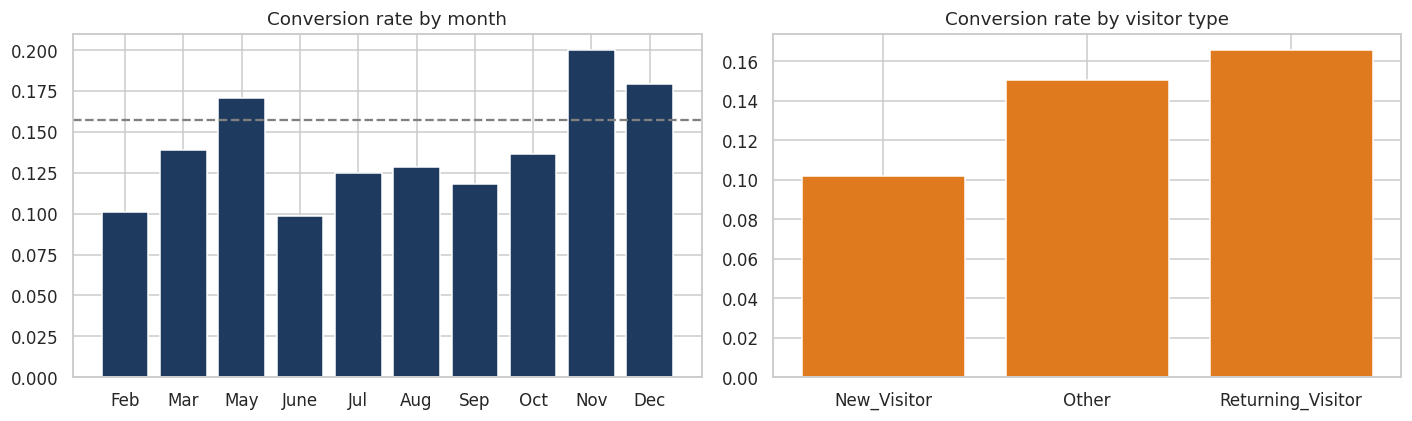

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = S.cols('months')
m = df.groupby('Month').Converted.agg(['mean','size']).reindex([x for x in order if x in df.Month.unique()])
ax[0].bar(m.index, m['mean'], color='#1F3A5F'); ax[0].axhline(df.Converted.mean(), ls='--', c='grey'); ax[0].set_title('Conversion rate by month')
v = df.groupby('VisitorType').Converted.agg(['mean','size'])
ax[1].bar(v.index, v['mean'], color='#E07A1F'); ax[1].set_title('Conversion rate by visitor type')
plt.tight_layout(); plt.show()
print(m.round(3)); print(v.round(3))

**Takeaway:** conversion is highest in Nov (20.0%) and May/Dec, lowest in Feb/June (about 10%); new visitors convert less (10.2%) than returning ones (16.6%). Month sizes are very uneven (Feb: 377 sessions, May: 3,554), so month effects for small months are noisy. Later we test whether Month adds anything once behaviour is known.

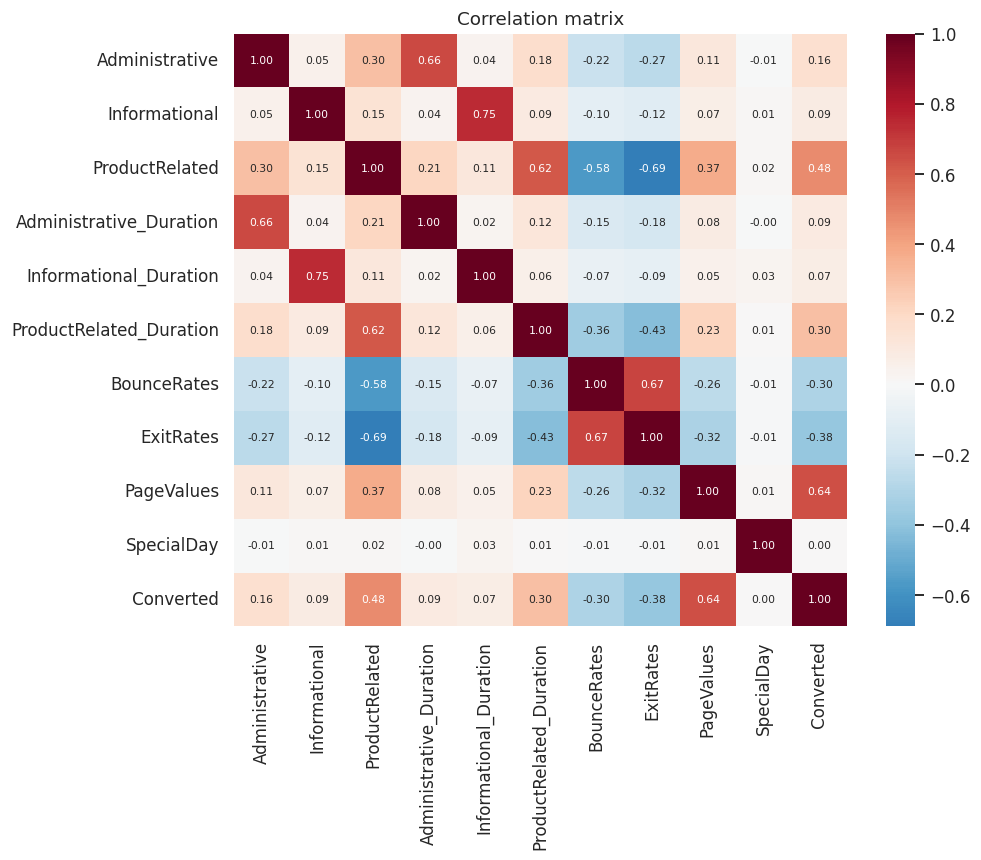

ExitRates                 -0.380588
BounceRates               -0.300734
SpecialDay                 0.003508
Informational_Duration     0.071471
Informational              0.086109
Administrative_Duration    0.090134
Administrative             0.160785
ProductRelated_Duration    0.298377
ProductRelated             0.477945
PageValues                 0.640159
Name: Converted, dtype: float64

In [5]:
num = ['Administrative','Informational','ProductRelated','Administrative_Duration','Informational_Duration','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay','Converted']
c = df[num].corr()
plt.figure(figsize=(9, 7)); sns.heatmap(c, annot=True, fmt='.2f', cmap='RdBu_r', center=0, annot_kws={'size': 7}); plt.title('Correlation matrix'); plt.show()
c['Converted'].drop('Converted').sort_values()

**Takeaway:** PageValues (0.64) and ProductRelated (0.48) are the strongest linear signals; ExitRates and BounceRates are negative and strongly correlated with each other (redundancy for linear models).

## The PageValues check (leakage decision)
The brief warns PageValues is partly a checkout-adjacent signal. Test it directly.

In [6]:
pv0 = df[df.PageValues == 0]; pv1 = df[df.PageValues > 0]
print(f'PageValues == 0: {len(pv0)} sessions ({len(pv0)/len(df):.1%}), purchases: {int(pv0.Converted.sum())}')
print(f'PageValues  > 0: {len(pv1)} sessions, conversion rate {pv1.Converted.mean():.1%}')

PageValues == 0: 6612 sessions (55.1%), purchases: 0
PageValues  > 0: 5388 sessions, conversion rate 35.0%


**Takeaway / decision:** *no session with PageValues = 0 ever converts* (0 of 6,612), i.e. PageValues is, in this data, a near-deterministic proxy for the outcome and in a live shop it is only known late (it reflects pages near checkout). A model using it would look excellent and be useless for early intervention. **Decision: the deployed model excludes PageValues**; a "with PageValues" run is reported only as a labelled upper bound (notebook 03).

In [7]:
rows = []
for col in S.cols('int_coded_categorical'):
    g = df.groupby(col).Converted.agg(['mean','size'])
    g = g[g['size'] >= 100]
    rows.append({'column': col, 'levels(n>=100)': len(g), 'min rate': g['mean'].min(), 'max rate': g['mean'].max()})
pd.DataFrame(rows).round(3)

,column,levels(n>=100),min rate,max rate
0,OperatingSystems,8,0.135,0.173
1,Browser,11,0.140,0.209
2,Region,9,0.128,0.171
3,TrafficType,20,0.130,0.214


**Takeaway:** the four int-coded ID columns are *categories* (Region 3 is not "more" than Region 1) and show nearly flat conversion across levels, so they are one-hot encoded, never scaled, and are candidates for removal in feature selection.

In [8]:
d = add_engineered_features(df)
print('sessions where BounceRates > ExitRates:', int((df.BounceRates > df.ExitRates).sum()),
      '(in Google Analytics a bounce is also an exit, so this is odd; kept as-is, flagged as a data-quality note)')
print('sessions with 0 pages of any type:', int((d.total_pages == 0).sum()))
print('Informational_Duration == 0 share:', round(float((df.Informational_Duration == 0).mean()), 3))

sessions where BounceRates > ExitRates: 463 (in Google Analytics a bounce is also an exit, so this is odd; kept as-is, flagged as a data-quality note)
sessions with 0 pages of any type: 1
Informational_Duration == 0 share: 0.585


**Takeaway:** 463 sessions have BounceRates above ExitRates, which should not happen in real GA data; the dataset is evidently synthetic (the brief says "realistic"), so conclusions describe this dataset, not a real shop. Durations are heavy-tailed with many zeros, hence log1p scaling in the pipeline.

In [9]:
# interactive chart (Plotly) - skipped automatically when plotly is not installed
try:
    import plotly.express as px
    fig = px.scatter(df.sample(3000, random_state=1), x='ProductRelated', y='ExitRates', color=df.sample(3000, random_state=1).Converted.astype(str),
                     opacity=.5, title='Product pages vs exit rate (interactive)', labels={'color': 'Converted'})
    fig.write_html(str(S.path('figures_dir') / 'eda_interactive.html'))
    print('saved reports/figures/eda_interactive.html')
except ImportError:
    print('plotly is not installed in this environment: interactive chart skipped (install plotly and re-run).')

plotly is not installed in this environment: interactive chart skipped (install plotly and re-run).
